# The Imbalance

(284807, 31)
0
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


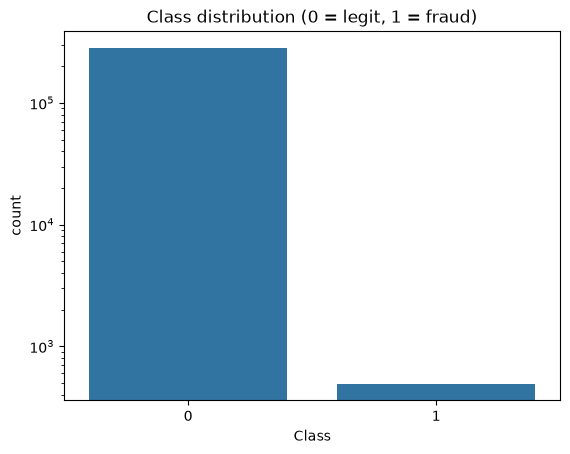

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\MDSystem1\Desktop\santhiya practice\DA Project\credit card fraud detection\data\creditcard.csv")

print(df.shape)
print(df.isnull().sum().sum())   # missing values
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True) * 100)
sns.countplot(x="Class", data=df)
plt.title("Class distribution (0 = legit, 1 = fraud)")
plt.yscale("log")   # log scale so fraud bars are visible
plt.savefig(r"C:\Users\MDSystem1\Desktop\santhiya practice\DA Project\credit card fraud detection\images\class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# The EDA

Duplicates: 0
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      283253.0   88.413575  250.379023  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.871860  260.211041  0.0  1.00   9.82  105.89   2125.87


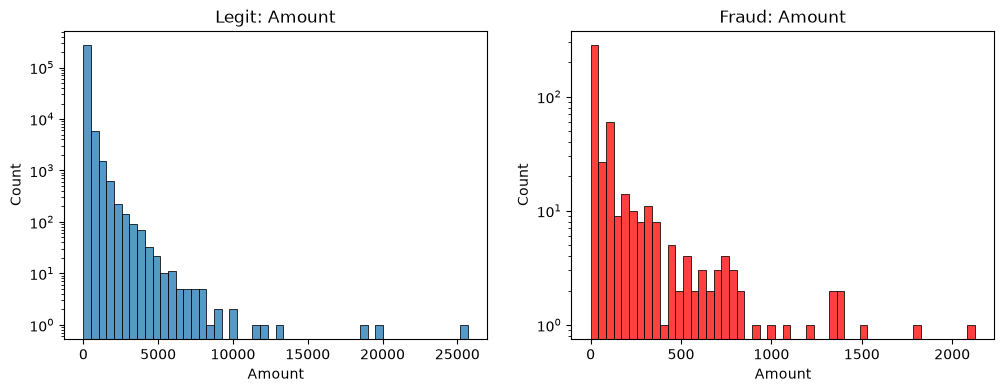

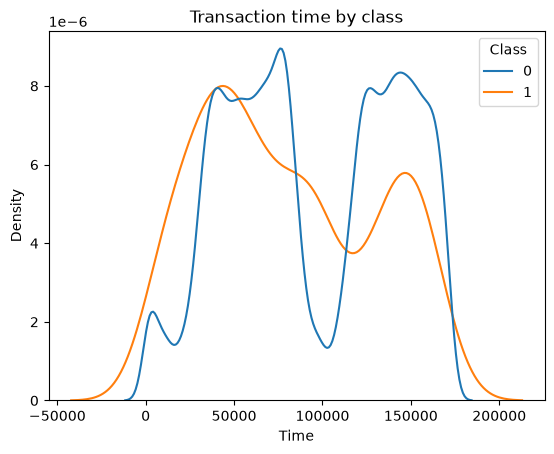

In [26]:
# 1. Duplicates
print("Duplicates:", df.duplicated().sum())

# 2. Amount summary by class
print(df.groupby("Class")["Amount"].describe())

# 3. Amount distribution by class
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[df.Class == 0]["Amount"], bins=50, ax=ax[0])
ax[0].set_title("Legit: Amount"); ax[0].set_yscale("log")
sns.histplot(df[df.Class == 1]["Amount"], bins=50, ax=ax[1], color="red")
ax[1].set_title("Fraud: Amount"); ax[1].set_yscale("log")
plt.savefig(r"C:\Users\MDSystem1\Desktop\santhiya practice\DA Project\credit card fraud detection\images\legit-fraud", dpi=150, bbox_inches="tight")
plt.show()

# 4. Time (seconds since first transaction, over ~2 days) by class
sns.kdeplot(data=df, x="Time", hue="Class", common_norm=False)
plt.title("Transaction time by class")
plt.savefig(r"C:\Users\MDSystem1\Desktop\santhiya practice\DA Project\credit card fraud detection\images\score_distribution", dpi=150, bbox_inches="tight")
plt.show()

# preprocessing and the train/test split

In [12]:
dups = df[df.duplicated(keep="first")]
print(dups["Class"].value_counts())

Class
0    1062
1      19
Name: count, dtype: int64


In [13]:
df = df.drop_duplicates().reset_index(drop=True)
print(df["Class"].value_counts())

Class
0    283253
1       473
Name: count, dtype: int64


# The baseline model

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = RobustScaler()
cols = ["Amount", "Time"]
X_train[cols] = scaler.fit_transform(X_train[cols])  # fit on train only
X_test[cols] = scaler.transform(X_test[cols])        # only transform test

print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Class
0    0.998335
1    0.001665
Name: proportion, dtype: float64
Class
0    0.998326
1    0.001674
Name: proportion, dtype: float64


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, average_precision_score,
                             roc_auc_score)

baseline = LogisticRegression(max_iter=1000, random_state=42)
baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_test)
y_prob = baseline.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, digits=4))
print("PR-AUC:", average_precision_score(y_test, y_prob))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.9991541254009093
[[56642     9]
 [   39    56]]
              precision    recall  f1-score   support

           0     0.9993    0.9998    0.9996     56651
           1     0.8615    0.5895    0.7000        95

    accuracy                         0.9992     56746
   macro avg     0.9304    0.7947    0.8498     56746
weighted avg     0.9991    0.9992    0.9991     56746

PR-AUC: 0.6950836125093012
ROC-AUC: 0.9575156846769092


# Dumb baseline

In [16]:
import numpy as np
dumb_pred = np.zeros(len(y_test))
print("Always-legit accuracy:", accuracy_score(y_test, dumb_pred))

Always-legit accuracy: 0.9983258731892997


# Imbalance handling

In [17]:
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    prob = model.predict_proba(X_te)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    return {
        "Model": name,
        "Precision": tp / (tp + fp) if (tp + fp) else 0,
        "Recall": tp / (tp + fn),
        "FP": fp, "FN": fn,
        "PR-AUC": average_precision_score(y_te, prob),
    }

results = []

results.append(evaluate("Baseline",
    LogisticRegression(max_iter=1000, random_state=42),
    X_train, y_train, X_test, y_test))

results.append(evaluate("Class weight",
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    X_train, y_train, X_test, y_test))

results.append(evaluate("Under-sampling",
    Pipeline([("sampler", RandomUnderSampler(random_state=42)),
              ("clf", LogisticRegression(max_iter=1000, random_state=42))]),
    X_train, y_train, X_test, y_test))

results.append(evaluate("SMOTE",
    Pipeline([("sampler", SMOTE(random_state=42)),
              ("clf", LogisticRegression(max_iter=1000, random_state=42))]),
    X_train, y_train, X_test, y_test))

pd.DataFrame(results).round(4)

,Model,Precision,Recall,FP,FN,PR-AUC
0,Baseline,0.8615,0.5895,9,39,0.6951
1,Class weight,0.0562,0.8737,1393,12,0.6719
2,Under-sampling,0.0508,0.8737,1552,12,0.6004
3,SMOTE,0.0537,0.8737,1463,12,0.6729


# Ensembles

In [18]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Ratio of legit to fraud in training data, for XGBoost weighting
spw = (y_train == 0).sum() / (y_train == 1).sum()

results.append(evaluate("Random Forest",
    RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                           min_samples_leaf=2, n_jobs=-1, random_state=42),
    X_train, y_train, X_test, y_test))

results.append(evaluate("XGBoost",
    XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                  scale_pos_weight=spw, eval_metric="aucpr",
                  n_jobs=-1, random_state=42),
    X_train, y_train, X_test, y_test))

pd.DataFrame(results).round(4)

,Model,Precision,Recall,FP,FN,PR-AUC
0,Baseline,0.8615,0.5895,9,39,0.6951
1,Class weight,0.0562,0.8737,1393,12,0.6719
2,Under-sampling,0.0508,0.8737,1552,12,0.6004
3,SMOTE,0.0537,0.8737,1463,12,0.6729
4,Random Forest,0.9583,0.7263,3,26,0.8119
5,XGBoost,0.9136,0.7789,7,21,0.8283


# Cross-validation and tuning

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                        min_samples_leaf=2, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                        scale_pos_weight=spw, eval_metric="aucpr",
                        n_jobs=-1, random_state=42),
}

for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=cv,
                             scoring="average_precision", n_jobs=1)
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std():.4f})")

Logistic Regression: 0.7550 (+/- 0.0304)
Random Forest: 0.8345 (+/- 0.0327)
XGBoost: 0.8466 (+/- 0.0238)


# Tune XGBoost (or the best performer)

In [20]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "scale_pos_weight": [1, 10, 50, spw],
}

search = RandomizedSearchCV(
    XGBClassifier(eval_metric="aucpr", n_jobs=-1, random_state=42),
    param_dist, n_iter=20, scoring="average_precision",
    cv=cv, random_state=42, n_jobs=1, verbose=1,
)
search.fit(X_train, y_train)
print(search.best_params_)
print("Best CV PR-AUC:", search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
{'subsample': 0.7, 'scale_pos_weight': 10, 'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
Best CV PR-AUC: 0.8575123343865746


# Threshold tuning, then the final test

In [21]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

best = search.best_estimator_

# 1. Out-of-fold probabilities on training data
oof_prob = cross_val_predict(best, X_train, y_train, cv=cv,
                             method="predict_proba", n_jobs=1)[:, 1]

# 2. Trade-off table at several thresholds
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (oof_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    rows.append({"Threshold": t,
                 "Precision": tp / (tp + fp) if (tp + fp) else 0,
                 "Recall": tp / (tp + fn),
                 "FP": fp, "FN": fn})
pd.DataFrame(rows).round(3)

,Threshold,Precision,Recall,FP,FN
0,0.1,0.866,0.841,49,60
1,0.2,0.903,0.839,34,61
2,0.3,0.913,0.828,30,65
3,0.4,0.915,0.825,29,66
4,0.5,0.925,0.820,25,68
5,0.6,0.939,0.812,20,71
6,0.7,0.944,0.807,18,73
7,0.8,0.946,0.788,17,80
8,0.9,0.954,0.767,14,88


In [22]:
# 3. Final evaluation on the untouched test set (run ONCE)
chosen_t = 0.3   # replace with your chosen threshold

test_prob = best.predict_proba(X_test)[:, 1]
for t in [0.5, chosen_t]:
    pred = (test_prob >= t).astype(int)
    print(f"--- Threshold {t} ---")
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, digits=4))
print("Test PR-AUC:", average_precision_score(y_test, test_prob))

--- Threshold 0.5 ---
[[56649     2]
 [   22    73]]
              precision    recall  f1-score   support

           0     0.9996    1.0000    0.9998     56651
           1     0.9733    0.7684    0.8588        95

    accuracy                         0.9996     56746
   macro avg     0.9865    0.8842    0.9293     56746
weighted avg     0.9996    0.9996    0.9996     56746

--- Threshold 0.3 ---
[[56647     4]
 [   22    73]]
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56651
           1     0.9481    0.7684    0.8488        95

    accuracy                         0.9995     56746
   macro avg     0.9738    0.8842    0.9243     56746
weighted avg     0.9995    0.9995    0.9995     56746

Test PR-AUC: 0.825836277837155


# Interpretation and error analysis

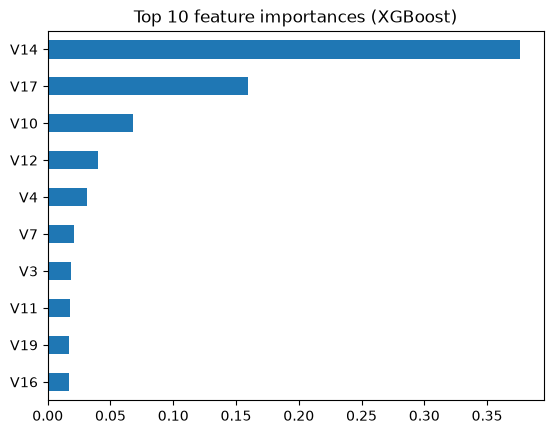

Missed fraud prob summary:
 count    22.000000
mean      0.022941
std       0.052139
min       0.000008
25%       0.000089
50%       0.000302
75%       0.010535
max       0.195330
Name: prob, dtype: float64
Caught fraud prob summary:
 count    73.000000
mean      0.976805
std       0.074596
min       0.555065
25%       0.994778
50%       0.997650
75%       0.998960
max       0.999841
Name: prob, dtype: float64
Amount (scaled) median, missed vs caught: -0.2782012195121951 0.15950665188470076


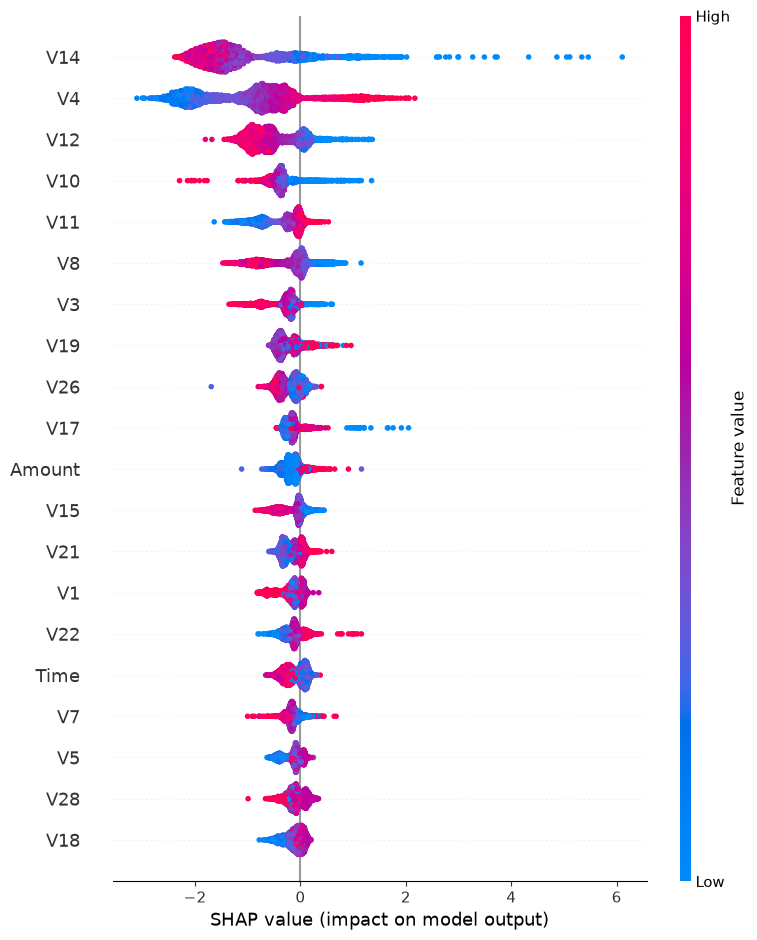

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Feature importance
imp = pd.Series(best.feature_importances_, index=X_train.columns).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind="barh", title="Top 10 feature importances (XGBoost)")
plt.savefig(r"C:\Users\MDSystem1\Desktop\santhiya practice\DA Project\credit card fraud detection\images\feature_importance.", dpi=150, bbox_inches="tight")
plt.show()

# 2. Missed frauds vs caught frauds
test_pred = (test_prob >= 0.5).astype(int)
res = X_test.copy()
res["Class"] = y_test.values
res["prob"] = test_prob
res["pred"] = test_pred

missed = res[(res.Class == 1) & (res.pred == 0)]
caught = res[(res.Class == 1) & (res.pred == 1)]
print("Missed fraud prob summary:\n", missed["prob"].describe())
print("Caught fraud prob summary:\n", caught["prob"].describe())
print("Amount (scaled) median, missed vs caught:",
      missed["Amount"].median(), caught["Amount"].median())
# 3. Optional: SHAP (pip install shap)
import shap
import matplotlib.pyplot as plt

# Take one fixed sample
X_shap = X_test.sample(5000, random_state=42)

# Calculate SHAP values
explainer = shap.TreeExplainer(best)
sv = explainer.shap_values(X_shap)

# Create SHAP summary plot
shap.summary_plot(sv, X_shap, show=False)

# Save image
plt.savefig(r"C:\Users\MDSystem1\Desktop\santhiya practice\DA Project\credit card fraud detection\images\shap_summary.png", dpi=300, bbox_inches="tight")

# Display it
plt.show()
plt.close()





Missed: count      22.000000
mean      172.389091
std       305.643102
min         0.000000
25%         0.800000
50%         2.005000
75%       266.497500
max      1096.990000
Name: Amount, dtype: float64
Caught: count      73.000000
mean      150.325342
std       314.884054
min         0.000000
25%         1.000000
50%        33.590000
75%       106.900000
max      1809.680000
Name: Amount, dtype: float64


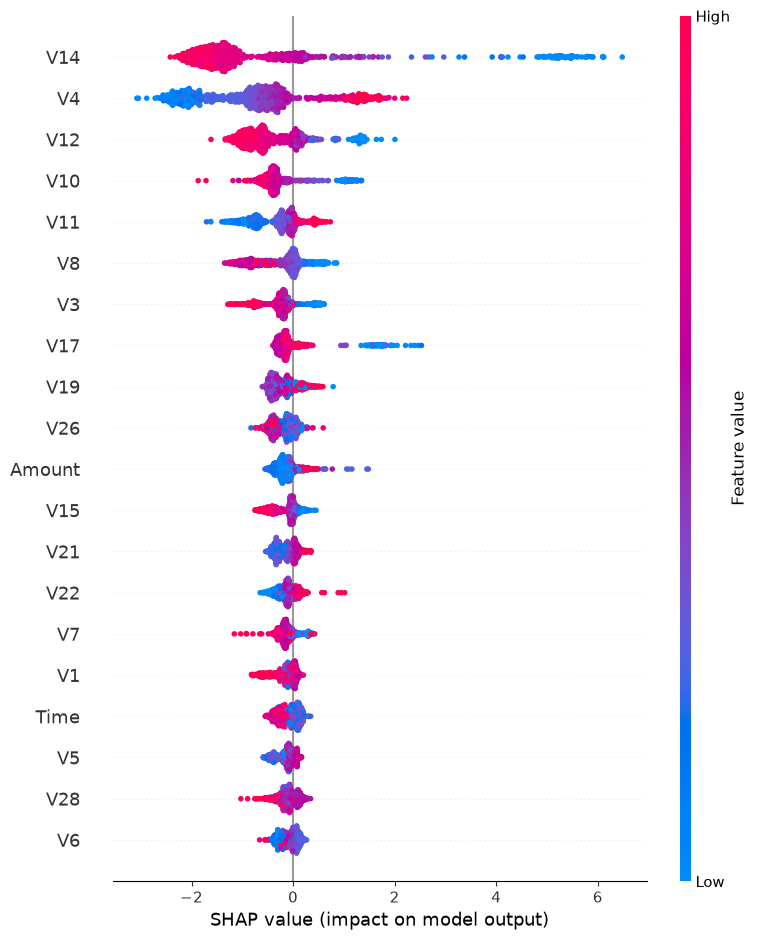

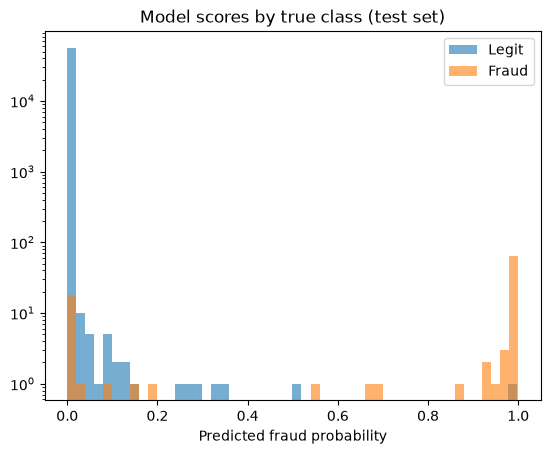

In [24]:
import shap

# 1. Raw amounts of missed vs caught frauds
print("Missed:", df.loc[missed.index, "Amount"].describe())
print("Caught:", df.loc[caught.index, "Amount"].describe())

# 2. Fraud-focused SHAP: all test frauds plus 1,000 legit rows
fraud_idx = y_test[y_test == 1].index
legit_idx = y_test[y_test == 0].sample(1000, random_state=42).index
X_shap = X_test.loc[fraud_idx.union(legit_idx)]
shap.summary_plot(explainer.shap_values(X_shap), X_shap)

# 3. Score distribution by class (a strong README chart)
plt.hist(res[res.Class == 0]["prob"], bins=50, alpha=0.6, label="Legit", log=True)
plt.hist(res[res.Class == 1]["prob"], bins=50, alpha=0.6, label="Fraud", log=True)
plt.xlabel("Predicted fraud probability"); plt.legend()
plt.title("Model scores by true class (test set)")
plt.show()